In [3]:
from astropy.io import fits
import fitsio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d, interpn
from scipy.signal import fftconvolve
from scipy.constants import pi, h, c, e, m_e, k, epsilon_0, physical_constants
import healpy as hp



In [4]:
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = 'cmr10' 
plt.rcParams['font.size'] = 15
plt.rcParams['axes.formatter.use_mathtext'] = True
plt.rc('axes', unicode_minus=False)

# Read in the ULSA Maps

In [ ]:
ulsa_map_path = # Path to luseepy output where sky model is ULSA map with no RRLs added
header   = dict(fitsio.read_header(ulsa_map_path))

with fits.open(ulsa_map_path) as f:
    ulsa_maps = f['data'].data
    freq_luseepy = f['freq'].data
    products = f["products"].data
    # Reconstruct complex blackbody normalization
    N = (
        f["blackbody_normalization_real"].data
        + 1j * f["blackbody_normalization_imag"].data
    )
    
    product_names = [p[0] for p in products]
    i00 = product_names.index("00R")
    ulsa_temp = ulsa_maps[:, i00, :] / N[:, 0, 0].real

rrl_freqs_path = # Path to list of frequencies where RRLs are center
rrl_freqs = np.sort(np.load(rrl_freqs_path))/1e6



In [6]:
# Average over time
mean_sky_brightness = np.mean(ulsa_temp, axis = 0)
mean_sky_brightness.shape

(361,)

# Calculate Stacked RRL Profiles

In [8]:
fmin = 10
fmax = 50

freq_ = np.arange(10e6, 50e6 + 25e3, 25e3, dtype=np.int32)
offsets = np.arange(-390.625 * 32, 390.625 * 32 + 10, 390.625/2)
freq = (freq_[:, None] + offsets).ravel()
spectrometer_freqs = np.unique(freq[(freq >= fmin * 1e6) & (freq <= fmax * 1e6)]) 

spectrometer_freqs.shape

(204801,)

In [9]:
window_width = 25 * 1e3 # Hz
channel_spacing = 390.625 / 2
num_channels = window_width / channel_spacing

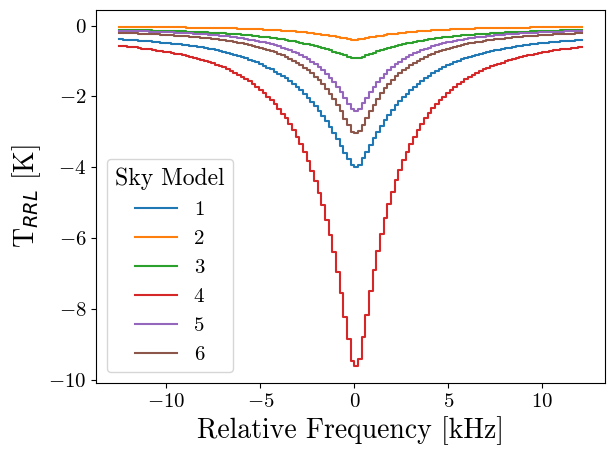

In [ ]:
stacked_profiles = []

for model in range(1,7): 
    path = ### Path to beam-diluted RRL spectra with spectrometer response applied. Shape is (time, frequency)
    rrl = np.load(path)
        
    windows = []
    n_ch = len(spectrometer_freqs)
    n_half = num_channels / 2

    for peak_freq in (rrl_freqs*1e6):
                
        # Get the frequency channel index that is closest to where the RRL peaks
        idx = np.searchsorted(spectrometer_freqs, peak_freq)
        if idx == 0:
            best_idx = 0
        elif idx == n_ch:
            best_idx = n_ch - 1
        else:
            left, right = idx - 1, idx
            best_idx = left if abs(spectrometer_freqs[left] - peak_freq) <= abs(spectrometer_freqs[right] - peak_freq) else right

        # Get the indices of the frequency channels that bound the window
        lo, hi = best_idx - n_half, best_idx + n_half - 1 
        
        # Drop lines whose window runs off the edges of 10-50 MHz
        if lo < 0 or hi > n_ch:
            continue
        
        windows.append({
            "line_freq": peak_freq,
            "center_idx": best_idx,
            "center_freq": spectrometer_freqs[best_idx],
            "misalignment_hz": spectrometer_freqs[best_idx] - peak_freq,
            "window_idx": np.arange(lo, hi, dtype=int),
        })
    
    time_avg_spectrum = np.mean(rrl, axis = 0)
    n_channels_per_window = len(windows[0]["window_idx"])

    stack = np.full((len(windows), n_channels_per_window), np.nan)

    for i, w in enumerate(windows):
        stack[i] = time_avg_spectrum[w["window_idx"]]
    
    stacked_profile = np.nanmean(stack, axis=0)
    n_stacked = np.sum(~np.isnan(stack), axis=0)
    
    rel_freq_axis = (np.arange(n_channels_per_window) - n_half) * channel_spacing
    
    stacked_profiles.append(stacked_profile)
    plt.plot(rel_freq_axis / 1e3, stacked_profile, drawstyle='steps-post', label = f"{model}")

stacked_profiles = np.array(stacked_profiles)

plt.xlabel("Relative Frequency [kHz]", fontsize = 20)
plt.ylabel(r"T$_{RRL}$ [K]", fontsize = 20)
#plt.title("Stacked RRLs")
plt.legend(title="Sky Model", title_fontsize = 17)
plt.tight_layout()
plt.show()
        


# Get the Individual Integration Times

In [17]:
fmin = 10
fmax = 50

freq_ = np.arange(10e6, 50e6 + 25e3, 25e3, dtype=np.int32)
offsets = np.arange(-390.625 * 32, 390.625 * 32 + 10, 390.625/2)
freq = (freq_[:, None] + offsets).ravel()
freqs = np.unique(freq[(freq >= fmin * 1e6) & (freq <= fmax * 1e6)]) 


In [18]:
SNR = 5
bandwidth = 390.625

In [22]:
integration_times = []

for model in range(1, 7):
    data = np.load(f"/global/cfs/projectdirs/m4895/users/fatimay/RRL_Sensitivity_Estimation/Spectrometer_Response_Modelling/RRL_Spectrometer_Response_Better_Resolution/Model-{model}.npy")
    
    points = (np.arange(0, 650), freqs/1e6)
    def interp_spectra(t, f):
        '''
        f is frequency in MHz
        t is time step (0-360)
        '''
        return interpn(points, data, [[t, f]], method='linear')
    
    interpolated_data = []
    for t in range(650):
        interpolated_data.append([interp_spectra(t = t, f = f) for f in rrl_freqs])
    interpolated_data = np.array(interpolated_data)[:, :, 0]
    mean_rrl_temp = np.mean(interpolated_data, axis = 0)
    
    nvals = np.arange(509, 870)

    ratio = mean_rrl_temp / mean_sky_brightness
    tau = ((SNR / ratio) ** 2) / bandwidth
        
    integration_times.append(tau)
    
integration_times = np.array(integration_times)
    

# Calculate the Stacked Integration Times

In [34]:
def stacked_integration_time(tau_i_target):
    """
    Compute the integration time needed to reach SNR = 5 by stacking
    N independent RRL lines, given each line's individual integration
    time tau_i required to reach snr_ref on its own.

    Parameters
    ----------
    tau_i : array of per-line integration times (any time unit) needed to individually reach snr=5
    """
    tau_i_target = np.asarray(tau_i_target, dtype=float)
    N = len(tau_i_target) 
    tau_stack = 1 / np.sum(1 / tau_i_target)
    
    return {
        "N": N,
        "tau_stack": tau_stack / 3600,  # convert seconds to hours
    }


In [35]:
model = 4
output = stacked_integration_time(integration_times[model - 1])

output

{'N': 361, 'tau_stack': np.float64(0.1799785297297388)}